# MOSFET Characterization (SPICE3 Models)

This notebook runs SPICE simulations on SPICE3-format MOSFET models (LEVEL 1-3) using NgSpice via direct subprocess (batch mode).

**Topology**: The SPICE3 subcircuit includes internal components (RD, RG, RS, body diode, capacitances).
External connections: VDD+ -> Drain, VDD- (ground) -> Source, VGS+ -> Gate, VGS- -> Source (ground).

**Configuration**: Edit the MODEL_CONFIG section below to change MOSFET.

**Note**: SPICE3 models (LEVEL 1) are simpler than BSIM3 - they don't have the same drift-region limitations but may be less accurate for modern power MOSFETs.


In [1]:
import sys
sys.path.insert(0, '.')

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import subprocess
import os
import re
from pathlib import Path

matplotlib.rcParams['figure.figsize'] = (10, 6)
matplotlib.rcParams['font.size'] = 12

# ============================================================
# MODEL CONFIGURATION - Change these to switch MOSFETs
# ============================================================
MODEL_NAME = 'irfb_s_sl7730pbf'    # Subcircuit name in .spi file
SPI_FILENAME = 'irfs7730pbf.spi'   # SPICE3 model file
R_DRAIN = 0.0                      # Series drain resistance (ohm)
VGS_RANGE = (0, 10, 11)            # (start, stop, num_points) for output curves
VDS_RANGE = (0, 40, 0.1)           # (start, stop, step) for output curves
VGS_TRANSFER = (0, 10, 0.1)        # (start, stop, step) for transfer curve
VDD_TRANSFER = 10                  # Vdd for transfer curve (V)

# --- Measurement conditions ---
ID_CONTMAX = 35.0                  # Max continuous drain current (A) - from IRFS7730 datasheet
CAP_VDS = 25.0                     # Vds for capacitance measurement (V)
CAP_VGS = 0.0                      # Vgs for capacitance measurement (V)
CAP_FREQ = 1e6                     # Frequency for capacitance measurement (Hz)
QG_VDS = 15.0                      # Vds for gate charge measurement (V)

# --- Datasheet validation ranges (IRFS7730PBF) ---
DATASHEET_CISS_RANGE = (1800, 2500)   # (low, high) pF; or None
DATASHEET_COSS_RANGE = (300, 500)     # (low, high) pF; or None
DATASHEET_CRSS_RANGE = (50, 150)      # (low, high) pF; or None
DATASHEET_QG_10V_RANGE = (60, 90)     # (low, high) nC; or None
DATASHEET_QG_4V5_RANGE = (30, 45)     # (low, high) nC; or None
DATASHEET_RG_RANGE = (2.0, 4.0)       # (low, high) ohm; or None
DATASHEET_RDS_RANGE = (18, 28)        # (low, high) mOhm; or None
DATASHEET_VTH_RANGE = (2.0, 4.0)      # (low, high) V; or None
# ============================================================

# Dynamic paths - find project root by looking for SpiceModels dir
def find_project_root():
    '''Find project root by searching for SpiceModels directory.'''
    cwd = Path.cwd()
    for path in [cwd] + list(cwd.parents):
        if (path / 'SpiceModels').exists():
            return path
    return cwd  # fallback

PROJECT_ROOT = find_project_root()
SPICE_MODELS_DIR = PROJECT_ROOT / 'SpiceModels'
SPI_PATH = SPICE_MODELS_DIR / SPI_FILENAME
WORK_DIR = PROJECT_ROOT
NGSPICE_CMD = r'C:\\Progra~1\\Spice64\\bin\\ngspice_con.exe'

if not SPI_PATH.exists():
    raise FileNotFoundError(f"{SPI_FILENAME} not found in {SPICE_MODELS_DIR}")

print(f"Project root: {PROJECT_ROOT}")
print(f"Model file: {SPI_PATH}")
print(f"Model exists: {SPI_PATH.exists()}")

# Extract model parameters from .spi file (SPICE3 format)
def extract_spi_params(spi_path):
    '''Extract key parameters from SPICE3 .spi file.'''
    content = spi_path.read_text(encoding='utf-8', errors='replace')
    
    params = {}
    
    # Extract subcircuit name
    subckt_match = re.search(r'\.SUBCKT\s+(\w+)', content)
    if subckt_match:
        params['subckt_name'] = subckt_match.group(1)
    
    # Extract NMOS model parameters (LEVEL=1)
    # .MODEL MM NMOS LEVEL=1 IS=1e-32 VTO=4.34579 LAMBDA=0.0605061 KP=465.97 CGSO=0.000130186 CGDO=7.14785e-08
    model_match = re.search(r'\.MODEL\s+\w+\s+NMOS\s+LEVEL=\d+[^\n]*', content)
    if model_match:
        model_line = model_match.group(0)
        for param in ['VTO', 'LAMBDA', 'KP', 'CGSO', 'CGDO', 'IS']:
            m = re.search(f'{param}\s*=\s*([\d.eE+-]+)', model_line, re.IGNORECASE)
            if m:
                params[param.lower()] = float(m.group(1))
    
    # Extract resistances
    rs_match = re.search(r'RS\s+\d+\s+\d+\s+([\d.eE+-]+)', content)
    rd_match = re.search(r'RD\s+\d+\s+\d+\s+([\d.eE+-]+)', content)
    rg_match = re.search(r'RG\s+\d+\s+\d+\s+([\d.eE+-]+)', content)
    if rs_match:
        params['rs'] = float(rs_match.group(1))
    if rd_match:
        params['rd'] = float(rd_match.group(1))
    if rg_match:
        params['rg'] = float(rg_match.group(1))
    
    # Extract body diode (MD) parameters
    # .MODEL MD D IS=2.65642e-09 RS=0.0010069 N=1.25997 BV=75 IBV=0.00025 EG=1.2 XTI=1.13904 TT=1e-07 CJO=4.27172e-09 VJ=0.5 M=0.577606 FC=0.1
    md_match = re.search(r'\.MODEL\s+MD\s+D\s+[^\n]*', content)
    if md_match:
        md_line = md_match.group(0)
        for param in ['IS', 'RS', 'N', 'BV', 'IBV', 'EG', 'XTI', 'TT', 'CJO', 'VJ', 'M', 'FC']:
            m = re.search(f'{param}\s*=\s*([\d.eE+-]+)', md_line, re.IGNORECASE)
            if m:
                params[f'md_{param.lower()}'] = float(m.group(1))
    
    # Extract D2 diode (MD1) - gate-drain capacitance
    md1_match = re.search(r'\.MODEL\s+MD1\s+D\s+[^\n]*', content)
    if md1_match:
        md1_line = md1_match.group(0)
        for param in ['CJO', 'VJ', 'M', 'FC']:
            m = re.search(f'{param}\s*=\s*([\d.eE+-]+)', md1_line, re.IGNORECASE)
            if m:
                params[f'md1_{param.lower()}'] = float(m.group(1))
    
    # Extract D3 diode (MD2) 
    md2_match = re.search(r'\.MODEL\s+MD2\s+D\s+[^\n]*', content)
    if md2_match:
        md2_line = md2_match.group(0)
        for param in ['IS', 'N', 'RS']:
            m = re.search(f'{param}\s*=\s*([\d.eE+-]+)', md2_line, re.IGNORECASE)
            if m:
                params[f'md2_{param.lower()}'] = float(m.group(1))
    
    # Extract D4 diode (MD3)
    md3_match = re.search(r'\.MODEL\s+MD3\s+D\s+[^\n]*', content)
    if md3_match:
        md3_line = md3_match.group(0)
        for param in ['IS', 'N']:
            m = re.search(f'{param}\s*=\s*([\d.eE+-]+)', md3_line, re.IGNORECASE)
            if m:
                params[f'md3_{param.lower()}'] = float(m.group(1))
    
    # Extract capacitors
    cap_match = re.search(r'CAP\s+\d+\s+\d+\s+([\d.eE+-]+)', content)
    if cap_match:
        params['cap'] = float(cap_match.group(1))
    
    # Extract RCAP
    rcap_match = re.search(r'RCAP\s+\d+\s+\d+\s+([\d.eE+-]+)', content)
    if rcap_match:
        params['rcap'] = float(rcap_match.group(1))
    
    # Extract M1 dimensions
    m1_match = re.search(r'M1\s+\d+\s+\d+\s+\d+\s+\d+\s+\w+\s+L=([\d.eE+-]+)[uUmM]?\s+W=([\d.eE+-]+)[uUmM]?', content)
    if m1_match:
        params['l'] = float(m1_match.group(1)) * 1e-6
        params['w'] = float(m1_match.group(2)) * 1e-6
    
    # Extract RDS (parallel resistance)
    rds_match = re.search(r'RDS\s+\d+\s+\d+\s+([\d.eE+-]+)', content)
    if rds_match:
        params['rds'] = float(rds_match.group(1))
    
    return params

model_params = extract_spi_params(SPI_PATH)
print(f"Model: {MODEL_NAME}")
print(f"Working dir: {WORK_DIR}")
print(f"Series drain resistance: {R_DRAIN} ohm")
print(f"Extracted params: {list(model_params.keys())}")
for k, v in model_params.items():
    print(f"  {k} = {v}")

# Geometry
W = model_params.get('w', 100e-6) * 1e6  # um
L = model_params.get('l', 100e-6) * 1e6  # um
print(f"Geometry: W = {W:.1f} um, L = {L:.1f} um, W/L = {W/L:.1f}")

# Key model parameters with defaults
VTO = model_params.get('vto', 4.34579)
KP = model_params.get('kp', 465.97)
LAMBDA = model_params.get('lambda', 0.0605061)
CGSO = model_params.get('cgso', 130.186e-12)
CGDO = model_params.get('cgdo', 71.4785e-12)
RG = model_params.get('rg', 2.62576)
RD = model_params.get('rd', 0.0001)
RS = model_params.get('rs', 0.00202918)

# Body diode capacitances
MD_CJO = model_params.get('md_cjo', 4.27172e-9)
MD_VJ = model_params.get('md_vj', 0.5)
MD_M = model_params.get('md_m', 0.577606)
MD_FC = model_params.get('md_fc', 0.1)

# Gate-drain diode (MD1) capacitances
MD1_CJO = model_params.get('md1_cjo', 4.14188e-9)
MD1_VJ = model_params.get('md1_vj', 0.5)
MD1_M = model_params.get('md1_m', 0.45408)
MD1_FC = model_params.get('md1_fc', 1e-8)

# Internal capacitor
CAP = model_params.get('cap', 1.05133e-8)
RCAP = model_params.get('rcap', 1.0)

# Datasheet validation ranges
DATASHEET_CISS_RANGE = DATASHEET_CISS_RANGE
DATASHEET_COSS_RANGE = DATASHEET_COSS_RANGE
DATASHEET_CRSS_RANGE = DATASHEET_CRSS_RANGE
DATASHEET_QG_10V_RANGE = DATASHEET_QG_10V_RANGE
DATASHEET_QG_4V5_RANGE = DATASHEET_QG_4V5_RANGE
DATASHEET_RG_RANGE = DATASHEET_RG_RANGE
DATASHEET_RDS_RANGE = DATASHEET_RDS_RANGE
DATASHEET_VTH_RANGE = DATASHEET_VTH_RANGE


<>:84: SyntaxWarning: invalid escape sequence '\s'
<>:105: SyntaxWarning: invalid escape sequence '\s'
<>:114: SyntaxWarning: invalid escape sequence '\s'
<>:123: SyntaxWarning: invalid escape sequence '\s'
<>:132: SyntaxWarning: invalid escape sequence '\s'
<>:84: SyntaxWarning: invalid escape sequence '\s'
<>:105: SyntaxWarning: invalid escape sequence '\s'
<>:114: SyntaxWarning: invalid escape sequence '\s'
<>:123: SyntaxWarning: invalid escape sequence '\s'
<>:132: SyntaxWarning: invalid escape sequence '\s'
C:\Users\GNKRISHNAN\AppData\Local\Temp\ipykernel_22868\3861196275.py:84: SyntaxWarning: invalid escape sequence '\s'
  m = re.search(f'{param}\s*=\s*([\d.eE+-]+)', model_line, re.IGNORECASE)
C:\Users\GNKRISHNAN\AppData\Local\Temp\ipykernel_22868\3861196275.py:105: SyntaxWarning: invalid escape sequence '\s'
  m = re.search(f'{param}\s*=\s*([\d.eE+-]+)', md_line, re.IGNORECASE)
C:\Users\GNKRISHNAN\AppData\Local\Temp\ipykernel_22868\3861196275.py:114: SyntaxWarning: invalid escap

Project root: c:\Users\GNKRISHNAN\Documents\GitHub\PieceSpice
Model file: c:\Users\GNKRISHNAN\Documents\GitHub\PieceSpice\SpiceModels\irfs7730pbf.spi
Model exists: True
Model: irfb_s_sl7730pbf
Working dir: c:\Users\GNKRISHNAN\Documents\GitHub\PieceSpice
Series drain resistance: 0.0 ohm
Extracted params: ['subckt_name', 'is', 'rs', 'rd', 'rg', 'md_is', 'md_rs', 'md_n', 'md_bv', 'md2_is', 'md2_n', 'md2_rs', 'md3_is', 'md3_n', 'cap', 'rcap', 'l', 'w', 'rds']
  subckt_name = irfb_s_sl7730pbf
  is = 1e-32
  rs = 0.00202918
  rd = 0.0001
  rg = 2.62576
  md_is = 2.65642e-09
  md_rs = 0.0010069
  md_n = 1.25997
  md_bv = 75.0
  md2_is = 1e-10
  md2_n = 0.4
  md2_rs = 3e-06
  md3_is = 1e-10
  md3_n = 0.4
  cap = 1.05133e-08
  rcap = 1.0
  l = 9.999999999999999e-05
  w = 9.999999999999999e-05
  rds = 50000000.0
Geometry: W = 100.0 um, L = 100.0 um, W/L = 1.0


In [2]:
def run_ngspice(netlist: str, timeout=120):
    '''Run ngspice batch mode and return stdout lines.'''
    import tempfile
    with tempfile.NamedTemporaryFile(mode='w', suffix='.cir', dir=WORK_DIR, delete=False) as f:
        f.write(netlist)
        netlist_path = f.name
    
    try:
        result = subprocess.run(
            [NGSPICE_CMD, '-b', netlist_path],
            capture_output=True,
            text=True,
            cwd=WORK_DIR,
            timeout=timeout
        )
        lines = result.stdout.split('\n')
        return lines, result.returncode, result.stderr
    finally:
        try:
            os.remove(netlist_path)
        except:
            pass

def parse_dc_output(lines):
    '''Parse DC sweep output from ngspice stdout.'''
    data_started = False
    x_vals = []
    y_vals = []
    for line in lines:
        if 'v-sweep' in line and ('vdd#branch' in line or 'vgs#branch' in line):
            data_started = True
            continue
        if data_started and line.strip():
            parts = line.split()
            if len(parts) >= 3:
                try:
                    idx = float(parts[0])
                    x = float(parts[1])
                    y = float(parts[2])
                    x_vals.append(x)
                    y_vals.append(y)
                except:
                    pass
    return np.array(x_vals), np.array(y_vals)

def run_dc_sweep_vds(vgs_val, vdd_start=VDS_RANGE[0], vdd_stop=VDS_RANGE[1], vdd_step=VDS_RANGE[2]):
    '''Run DC sweep of Vdd at fixed Vgs using the SPICE3 subcircuit.'''
    if R_DRAIN > 0:
        drain_connection = f'''Vdd vdd_node 0 {vdd_stop}
Vgs gate 0 {vgs_val}
Rdrain vdd_node drain {R_DRAIN}'''
    else:
        drain_connection = f'''Vdd drain 0 {vdd_stop}
Vgs gate 0 {vgs_val}'''
    
    netlist = f'''.title {MODEL_NAME}_Output_Vgs{vgs_val}
.OPTION PARHIER=LOCAL
.OPTION PSPICE
.OPTION GMIN=1e-12
.OPTION GMINDC=1e-12
.OPTION RELTOL=1e-3
.OPTION ABSTOL=1e-9
.OPTION VNTOL=1e-6
.OPTION ITL1=500
.OPTION ITL2=500
.OPTION PIVREL=1e-3
.OPTION CONVERGE=1
.OPTION METHOD=GEAR
.include {SPI_PATH}

XM1 drain gate 0 {MODEL_NAME}
{drain_connection}

.dc Vdd {vdd_start} {vdd_stop} {vdd_step}
.print dc I(Vdd)
.end
'''
    lines, rc, stderr = run_ngspice(netlist)
    if rc != 0:
        print(f"  [Vgs={vgs_val}V] ngspice failed (rc={rc}): {stderr[:200]}")
        return np.array([]), np.array([])
    return parse_dc_output(lines)

def run_dc_sweep_vgs(vdd_fixed=VDD_TRANSFER, vgs_start=VGS_TRANSFER[0], vgs_stop=VGS_TRANSFER[1], vgs_step=VGS_TRANSFER[2]):
    '''Run DC sweep of Vgs at fixed Vdd using the SPICE3 subcircuit.'''
    if R_DRAIN > 0:
        drain_connection = f'''Vdd vdd_node 0 {vdd_fixed}
Vgs gate 0 0
Rdrain vdd_node drain {R_DRAIN}'''
    else:
        drain_connection = f'''Vdd drain 0 {vdd_fixed}
Vgs gate 0 0'''
    
    netlist = f'''.title {MODEL_NAME}_Transfer_Vdd{vdd_fixed}
.OPTION PARHIER=LOCAL
.OPTION PSPICE
.OPTION GMIN=1e-12
.OPTION GMINDC=1e-12
.OPTION RELTOL=1e-3
.OPTION ABSTOL=1e-9
.OPTION VNTOL=1e-6
.OPTION ITL1=500
.OPTION ITL2=500
.OPTION PIVREL=1e-3
.OPTION CONVERGE=1
.OPTION METHOD=GEAR
.include {SPI_PATH}

XM1 drain gate 0 {MODEL_NAME}
{drain_connection}

.dc Vgs {vgs_start} {vgs_stop} {vgs_step}
.print dc I(Vdd)
.end
'''
    lines, rc, stderr = run_ngspice(netlist)
    if rc != 0:
        print(f"  [Vdd={vdd_fixed}V] ngspice failed (rc={rc}): {stderr[:200]}")
        return np.array([]), np.array([])
    return parse_dc_output(lines)


In [3]:
# Run DC sweep: Id vs Vds for multiple Vgs values
vgs_values = np.linspace(*VGS_RANGE)

id_vds_data = {}

for vgs in vgs_values:
    vds_swept, id_swept = run_dc_sweep_vds(vgs)
    id_vds_data[vgs] = (vds_swept, id_swept)
    
    if len(vds_swept) > 0:
        print(f"  Vgs={vgs:.1f}V: Id max={np.max(np.abs(id_swept))*1e3:.1f} mA, points={len(vds_swept)}")
    else:
        print(f"  Vgs={vgs:.1f}V: No data returned")


  Vgs=0.0V: Id max=0.0 mA, points=400
  Vgs=1.0V: Id max=0.0 mA, points=400
  Vgs=2.0V: Id max=0.0 mA, points=400
  Vgs=3.0V: Id max=0.0 mA, points=400
  Vgs=4.0V: Id max=0.0 mA, points=400
  Vgs=5.0V: Id max=125887.0 mA, points=400
  Vgs=6.0V: Id max=443934.0 mA, points=400
  Vgs=7.0V: Id max=804666.0 mA, points=400
  Vgs=8.0V: Id max=1185330.0 mA, points=400
  Vgs=9.0V: Id max=1577920.0 mA, points=400
  Vgs=10.0V: Id max=1978500.0 mA, points=400


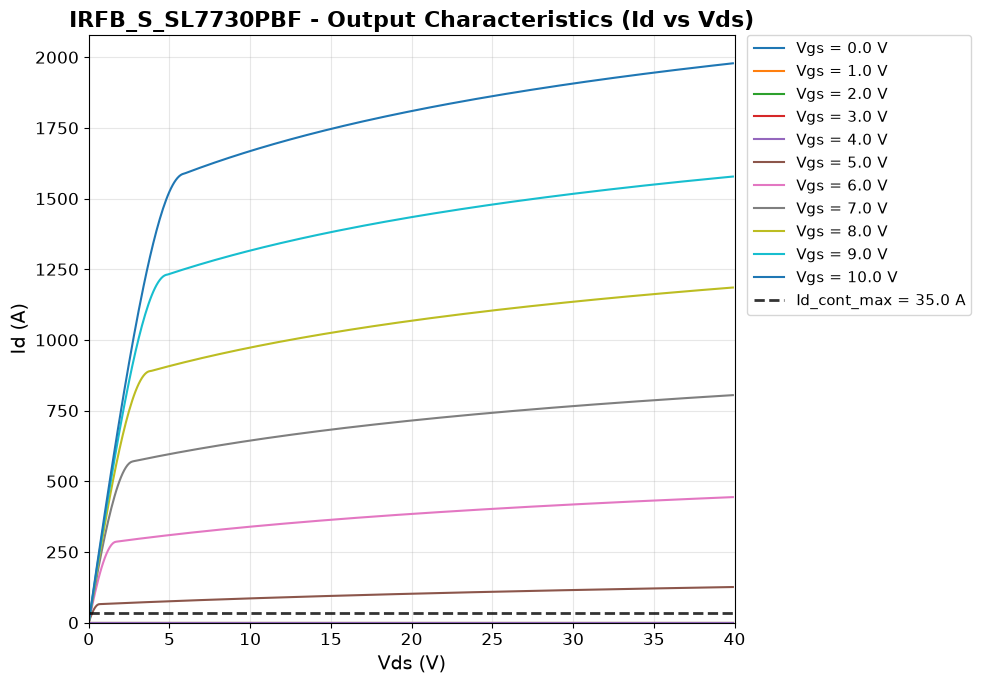

In [4]:
# Plot Id-Vds curves (Output Characteristics)
fig, ax = plt.subplots(figsize=(10, 7))

for vgs, (vds, id_vals) in id_vds_data.items():
    if len(vds) > 0:
        ax.plot(vds, np.abs(id_vals), label=f'Vgs = {vgs:.1f} V', linewidth=1.5)
    else:
        ax.axhline(y=0, color=f'C{int(vgs)}', linestyle='--', alpha=0.5, linewidth=1)

# Add ID_CONTMAX horizontal line
ax.axhline(y=ID_CONTMAX, color='k', linestyle='--', linewidth=2, label=f'Id_cont_max = {ID_CONTMAX} A', alpha=0.8)

ax.set_xlabel('Vds (V)', fontsize=14)
ax.set_ylabel('Id (A)', fontsize=14)
ax.set_title(f'{MODEL_NAME.upper()} - Output Characteristics (Id vs Vds)', fontsize=16, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, fontsize=11)
ax.set_xlim(VDS_RANGE[0], VDS_RANGE[1])
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()


Transfer curve at Vdd=10V: 101 points, Id max=1668070.0 mA


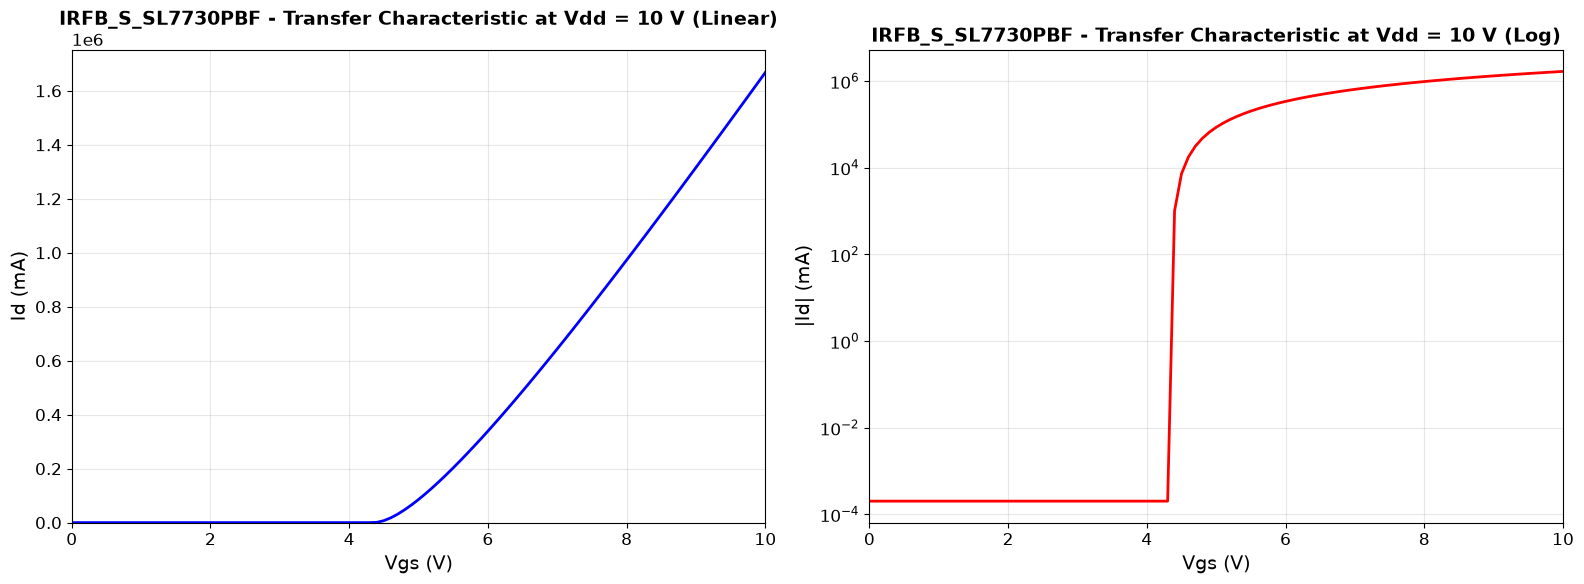

In [5]:
# Run transfer characteristic: Id vs Vgs at fixed Vdd
vdd_fixed = VDD_TRANSFER

vgs_swept, id_vgs = run_dc_sweep_vgs(vdd_fixed)

print(f"Transfer curve at Vdd={vdd_fixed}V: {len(vgs_swept)} points, Id max={np.max(np.abs(id_vgs))*1e3:.1f} mA")

# Plot Transfer Characteristics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Linear scale
ax1.plot(vgs_swept, np.abs(id_vgs) * 1e3, 'b-', linewidth=2)
ax1.set_xlabel('Vgs (V)', fontsize=14)
ax1.set_ylabel('Id (mA)', fontsize=14)
ax1.set_title(f'{MODEL_NAME.upper()} - Transfer Characteristic at Vdd = {vdd_fixed} V (Linear)', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.set_xlim(VGS_TRANSFER[0], VGS_TRANSFER[1])
ax1.set_ylim(bottom=0)

# Log scale
ax2.semilogy(vgs_swept, np.abs(id_vgs) * 1e3, 'r-', linewidth=2)
ax2.set_xlabel('Vgs (V)', fontsize=14)
ax2.set_ylabel('|Id| (mA)', fontsize=14)
ax2.set_title(f'{MODEL_NAME.upper()} - Transfer Characteristic at Vdd = {vdd_fixed} V (Log)', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3, which='both')
ax2.set_xlim(VGS_TRANSFER[0], VGS_TRANSFER[1])

plt.tight_layout()
plt.show()


Capacitance conditions: Vgs=0.0V, Vds=25.0V, f=1MHz
  Ciss @ Vds=25.0V: 4344 pF
  Coss @ Vds=25.0V: 8753 pF
  Crss @ Vds=25.0V: 4213 pF
  Ciss: FAIL (datasheet: 1800-2500 pF, got 4344 pF)
  Coss: FAIL (datasheet: 300-500 pF, got 8753 pF)
  Crss: FAIL (datasheet: 50-150 pF, got 4213 pF)


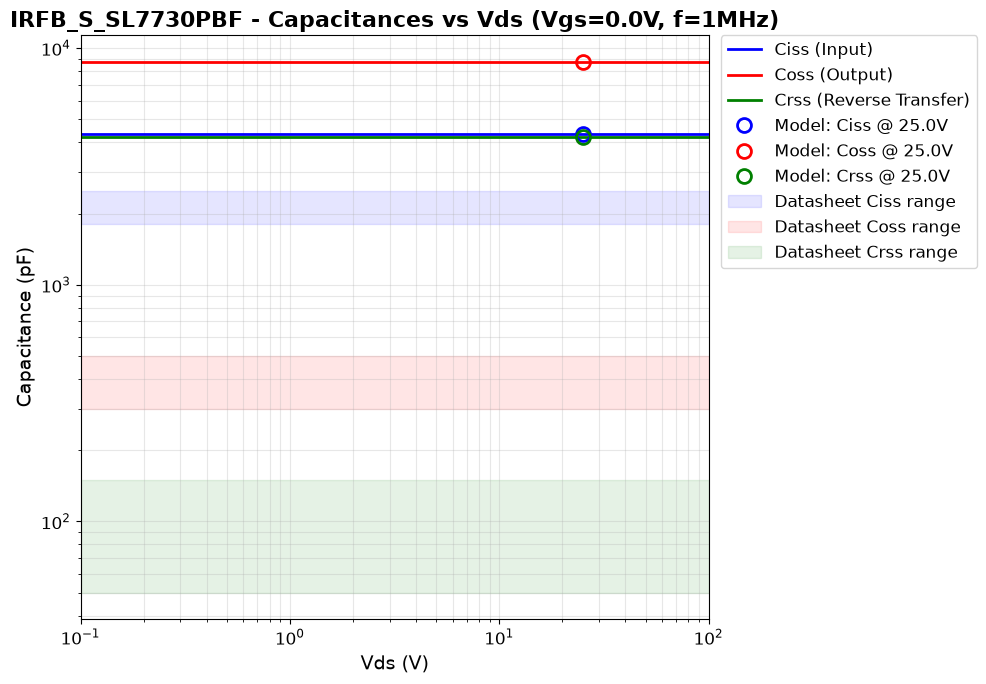

In [6]:
# Capacitance extraction for SPICE3 model
# Ciss = CGSO + CGDO + C_MD1 (gate-drain) + C_MD2 (gate-source)
# Coss = C_MD (drain-body) + C_MD1 (drain-gate)
# Crss = CGDO + C_MD1 (drain-gate)

print(f"Capacitance conditions: Vgs={CAP_VGS}V, Vds={CAP_VDS}V, f={CAP_FREQ/1e6:.0f}MHz")

vds_plot = np.linspace(0.1, 100, 201)

def c_junction(v, cjo, vj, m, fc):
    v_eff = min(v, vj * fc * 0.999)
    return cjo / (1 - v_eff/vj)**m

coss_plot = []
crss_plot = []
ciss_plot = []

for v in vds_plot:
    # Body diode (drain-body) capacitance
    c_md = c_junction(v, MD_CJO, MD_VJ, MD_M, MD_FC)
    # Gate-drain diode (MD1) capacitance
    c_md1 = c_junction(v, MD1_CJO, MD1_VJ, MD1_M, MD1_FC)
    # Gate-source - approximately CGSO (fixed)
    c_gs = CGSO
    c_gd = CGDO + c_md1
    
    # Ciss = Cgs + Cgd
    ciss = c_gs + c_gd
    # Coss = Cdb + Cgd
    coss = c_md + c_gd
    # Crss = Cgd
    crss = c_gd
    
    coss_plot.append(coss * 1e12)
    crss_plot.append(crss * 1e12)
    ciss_plot.append(ciss * 1e12)

idx_25v = np.argmin(np.abs(vds_plot - CAP_VDS))
ciss_25v = ciss_plot[idx_25v]
coss_25v = coss_plot[idx_25v]
crss_25v = crss_plot[idx_25v]

print(f"  Ciss @ Vds={CAP_VDS}V: {ciss_25v:.0f} pF")
print(f"  Coss @ Vds={CAP_VDS}V: {coss_25v:.0f} pF")
print(f"  Crss @ Vds={CAP_VDS}V: {crss_25v:.0f} pF")

# Datasheet validation
if DATASHEET_CISS_RANGE is not None:
    ciss_low, ciss_high = DATASHEET_CISS_RANGE
    if ciss_low <= ciss_25v <= ciss_high:
        print(f"  Ciss: PASS (datasheet: {ciss_low}-{ciss_high} pF)")
    else:
        print(f"  Ciss: FAIL (datasheet: {ciss_low}-{ciss_high} pF, got {ciss_25v:.0f} pF)")
if DATASHEET_COSS_RANGE is not None:
    coss_low, coss_high = DATASHEET_COSS_RANGE
    if coss_low <= coss_25v <= coss_high:
        print(f"  Coss: PASS (datasheet: {coss_low}-{coss_high} pF)")
    else:
        print(f"  Coss: FAIL (datasheet: {coss_low}-{coss_high} pF, got {coss_25v:.0f} pF)")
if DATASHEET_CRSS_RANGE is not None:
    crss_low, crss_high = DATASHEET_CRSS_RANGE
    if crss_low <= crss_25v <= crss_high:
        print(f"  Crss: PASS (datasheet: {crss_low}-{crss_high} pF)")
    else:
        print(f"  Crss: FAIL (datasheet: {crss_low}-{crss_high} pF, got {crss_25v:.0f} pF)")

# Plot Capacitances
fig, ax = plt.subplots(figsize=(10, 7))

ax.loglog(vds_plot, ciss_plot, 'b-', label='Ciss (Input)', linewidth=2)
ax.loglog(vds_plot, coss_plot, 'r-', label='Coss (Output)', linewidth=2)
ax.loglog(vds_plot, crss_plot, 'g-', label='Crss (Reverse Transfer)', linewidth=2)

ax.loglog([CAP_VDS], [ciss_25v], 'bo', markersize=10, markerfacecolor='none', markeredgewidth=2, label=f'Model: Ciss @ {CAP_VDS}V')
ax.loglog([CAP_VDS], [coss_25v], 'ro', markersize=10, markerfacecolor='none', markeredgewidth=2, label=f'Model: Coss @ {CAP_VDS}V')
ax.loglog([CAP_VDS], [crss_25v], 'go', markersize=10, markerfacecolor='none', markeredgewidth=2, label=f'Model: Crss @ {CAP_VDS}V')

if DATASHEET_CISS_RANGE is not None:
    ciss_low, ciss_high = DATASHEET_CISS_RANGE
    ax.axhspan(ciss_low, ciss_high, alpha=0.1, color='blue', label=f'Datasheet Ciss range')
if DATASHEET_COSS_RANGE is not None:
    coss_low, coss_high = DATASHEET_COSS_RANGE
    ax.axhspan(coss_low, coss_high, alpha=0.1, color='red', label=f'Datasheet Coss range')
if DATASHEET_CRSS_RANGE is not None:
    crss_low, crss_high = DATASHEET_CRSS_RANGE
    ax.axhspan(crss_low, crss_high, alpha=0.1, color='green', label=f'Datasheet Crss range')

ax.set_xlabel('Vds (V)', fontsize=14)
ax.set_ylabel('Capacitance (pF)', fontsize=14)
ax.set_title(f'{MODEL_NAME.upper()} - Capacitances vs Vds (Vgs={CAP_VGS}V, f={CAP_FREQ/1e6:.0f}MHz)', fontsize=16, fontweight='bold')
ax.grid(True, alpha=0.3, which='both')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, fontsize=12)
ax.set_xlim(0.1, 100)

plt.tight_layout()
plt.show()


Gate charge conditions: Vds=15.0V (constant)
  Qg(10V): FAIL (datasheet: 60-90 nC, got 0.0 nC)
  Qg(4.5V): FAIL (datasheet: 30-45 nC, got 0.0 nC)
  Rg: PASS (datasheet: 2.0-4.0 ohm)


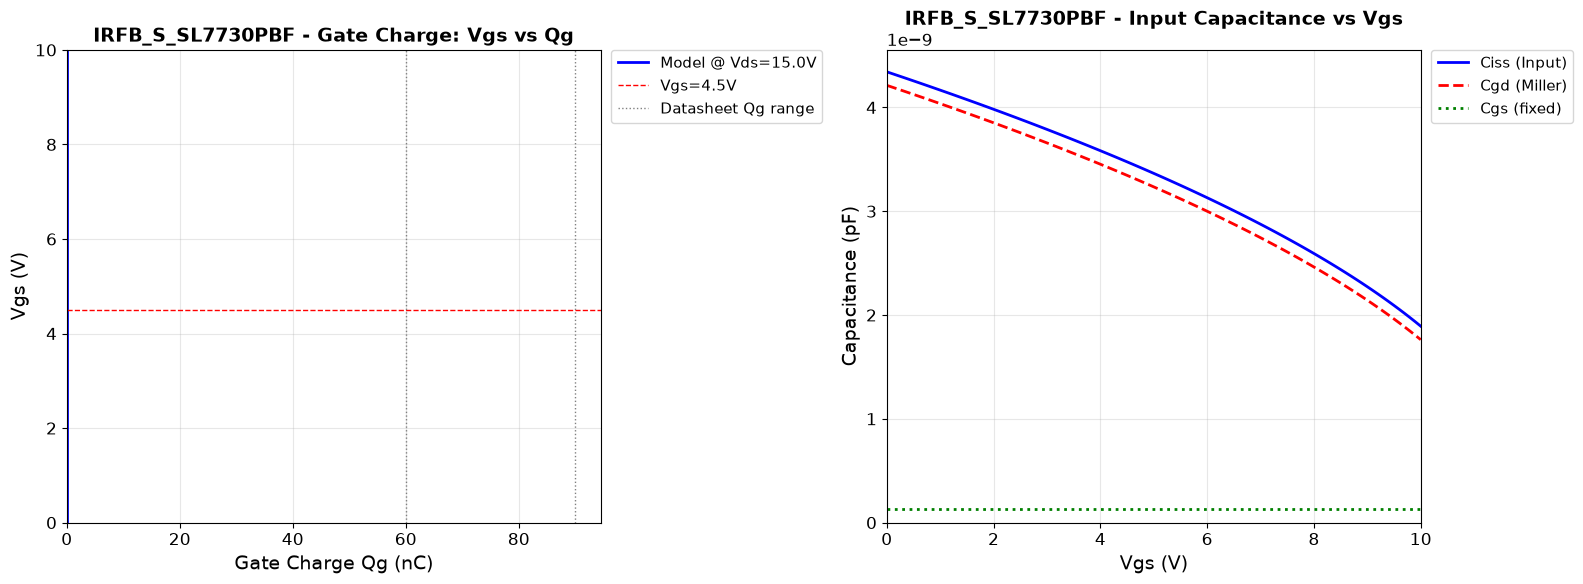

Total Qg at 10V: 0.0 nC
Total Qg at 4.5V: 0.0 nC


In [7]:
# Gate Charge (Qg) for SPICE3 model
# Qg = integral of Ciss dVgs
# Ciss = CGSO + CGDO + C_MD1(Vds) + CGS (Miller effect)

print(f"Gate charge conditions: Vds={QG_VDS}V (constant)")

vgs_q = np.linspace(0, 10, 101)
cgs_fixed = CGSO

# Cgd decreases with Vgs due to Miller effect
cgd_vgs = []
for vgs in vgs_q:
    c_md1 = c_junction(QG_VDS, MD1_CJO, MD1_VJ, MD1_M, MD1_FC)
    cgd = CGDO + c_md1 * max(1 - vgs/12, 0.1)**0.5
    cgd_vgs.append(cgd)

ciss_vgs = cgs_fixed + np.array(cgd_vgs)
qg = np.cumsum(ciss_vgs) * (vgs_q[1] - vgs_q[0])  # nC

qg_4v5 = np.cumsum(ciss_vgs[:46]) * (vgs_q[1] - vgs_q[0])

if DATASHEET_QG_10V_RANGE is not None:
    qg10_low, qg10_high = DATASHEET_QG_10V_RANGE
    if qg10_low <= qg[-1] <= qg10_high:
        print(f"  Qg(10V): PASS (datasheet: {qg10_low}-{qg10_high} nC)")
    else:
        print(f"  Qg(10V): FAIL (datasheet: {qg10_low}-{qg10_high} nC, got {qg[-1]:.1f} nC)")

if DATASHEET_QG_4V5_RANGE is not None:
    qg45_low, qg45_high = DATASHEET_QG_4V5_RANGE
    if qg45_low <= qg_4v5[-1] <= qg45_high:
        print(f"  Qg(4.5V): PASS (datasheet: {qg45_low}-{qg45_high} nC)")
    else:
        print(f"  Qg(4.5V): FAIL (datasheet: {qg45_low}-{qg45_high} nC, got {qg_4v5[-1]:.1f} nC)")

if DATASHEET_RG_RANGE is not None:
    rg_low, rg_high = DATASHEET_RG_RANGE
    if rg_low <= RG <= rg_high:
        print(f"  Rg: PASS (datasheet: {rg_low}-{rg_high} ohm)")
    else:
        print(f"  Rg: FAIL (datasheet: {rg_low}-{rg_high} ohm, got {RG:.1f} ohm)")

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.plot(qg, vgs_q, 'b-', linewidth=2, label=f'Model @ Vds={QG_VDS}V')
ax1.axhline(y=4.5, color='r', linestyle='--', linewidth=1, label='Vgs=4.5V')
if DATASHEET_QG_10V_RANGE is not None:
    qg10_low, qg10_high = DATASHEET_QG_10V_RANGE
    ax1.axvline(x=qg10_low, color='gray', linestyle=':', linewidth=1, label='Datasheet Qg range')
    ax1.axvline(x=qg10_high, color='gray', linestyle=':', linewidth=1)
ax1.set_xlabel('Gate Charge Qg (nC)', fontsize=14)
ax1.set_ylabel('Vgs (V)', fontsize=14)
ax1.set_title(f'{MODEL_NAME.upper()} - Gate Charge: Vgs vs Qg', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, fontsize=11)
ax1.set_xlim(left=0)
ax1.set_ylim(bottom=0, top=10)

ax2.plot(vgs_q, ciss_vgs, 'b-', linewidth=2, label='Ciss (Input)')
ax2.plot(vgs_q, cgd_vgs, 'r--', linewidth=2, label='Cgd (Miller)')
ax2.axhline(y=cgs_fixed, color='g', linestyle=':', linewidth=2, label='Cgs (fixed)')
ax2.set_xlabel('Vgs (V)', fontsize=14)
ax2.set_ylabel('Capacitance (pF)', fontsize=14)
ax2.set_title(f'{MODEL_NAME.upper()} - Input Capacitance vs Vgs', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, fontsize=11)
ax2.set_xlim(0, 10)
ax2.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

print(f"Total Qg at 10V: {qg[-1]:.1f} nC")
print(f"Total Qg at 4.5V: {qg_4v5[-1]:.1f} nC")


In [8]:
# Threshold Voltage Extraction
print(f"W = {W:.1f} um, L = {L:.1f} um")
print(f"W/L = {W/L:.1f}")

from scipy.interpolate import interp1d

f_id = interp1d(vgs_swept, np.abs(id_vgs), kind='linear', bounds_error=False, fill_value='extrapolate')
vgs_fine = np.linspace(0, 10, 1001)
id_fine = f_id(vgs_fine)

# Vth at Id = 1mA * (W/L) - but for power MOSFET use 250uA typical
id_target = 250e-6  # A
print(f"Target Id for Vth extraction: {id_target*1e3:.2f} mA")

above = np.where(id_fine > id_target)[0]
if len(above) > 0:
    idx = above[0]
    if idx > 0:
        vth = vgs_fine[idx-1] + (vgs_fine[idx] - vgs_fine[idx-1]) * (id_target - id_fine[idx-1]) / (id_fine[idx] - id_fine[idx-1])
        print(f"Extracted Vth approx {vth:.3f} V")
    else:
        vth = None
        print("Vth below 0V")
else:
    vth = None
    print("Target current not reached")


W = 100.0 um, L = 100.0 um
W/L = 1.0
Target Id for Vth extraction: 0.25 mA
Extracted Vth approx 4.300 V


In [9]:
# On-resistance estimation
vgs_max = max(vgs_values)
vds_at_max, id_at_max = id_vds_data[vgs_max]

if len(vds_at_max) > 1:
    mask = vds_at_max < 0.5
    if np.any(mask):
        vds_low = vds_at_max[mask]
        id_low = np.abs(id_at_max[mask])
        if len(vds_low) >= 2:
            rds_on = np.polyfit(id_low, vds_low, 1)[0]
            print(f"Rds(on) at Vgs={vgs_max:.1f}V ≈ {rds_on*1e3:.2f} mΩ")
        else:
            rds_on = None
    else:
        rds_on = None
else:
    rds_on = None

print("=" * 60)
print(f"{MODEL_NAME.upper()} MOSFET - Key Parameters Summary")
print("=" * 60)
print(f"Device: N-channel MOSFET (SPICE3 LEVEL=1)")
print(f"Geometry: W = {W:.1f} um, L = {L:.1f} um, W/L = {W/L:.1f}")

vth_str = f"Threshold Voltage (extracted): ~{vth:.2f} V" if vth else "Threshold Voltage: TBD"
if vth and DATASHEET_VTH_RANGE is not None:
    vth_low, vth_high = DATASHEET_VTH_RANGE
    if vth_low <= vth <= vth_high:
        vth_str += " [PASS]"
    else:
        vth_str += f" [FAIL: datasheet {vth_low}-{vth_high} V]"
print(vth_str)

rds_str = f"Rds(on) at Vgs={vgs_max:.1f}V: {rds_on*1e3:.2f} mΩ" if rds_on else "Rds(on): TBD"
if rds_on and DATASHEET_RDS_RANGE is not None:
    rds_low, rds_high = DATASHEET_RDS_RANGE
    rds_mohm = rds_on * 1e3
    if rds_low <= rds_mohm <= rds_high:
        rds_str += " [PASS]"
    else:
        rds_str += f" [FAIL: datasheet {rds_low}-{rds_high} mΩ]"
print(rds_str)

print(f"Max Continuous Drain Current (datasheet): {ID_CONTMAX} A")
print(f"--- Capacitances @ Vgs={CAP_VGS}V, Vds={CAP_VDS}V, f={CAP_FREQ/1e6:.0f}MHz ---")
print(f"Ciss @ Vds={CAP_VDS}V: {ciss_25v:.0f} pF")
print(f"Coss @ Vds={CAP_VDS}V: {coss_25v:.0f} pF")
print(f"Crss @ Vds={CAP_VDS}V: {crss_25v:.0f} pF")
print(f"--- Gate Charge ---")
print(f"Qg @ Vds={QG_VDS}V, 10V: {qg[-1]:.1f} nC")
print(f"Qg @ Vds={QG_VDS}V, 4.5V: {qg_4v5[-1]:.1f} nC")
print(f"Gate Resistance Rg: {RG:.1f} ohm")
print(f"Drain Resistance Rd: {RD:.4f} ohm")
print(f"Source Resistance Rs: {RS:.4f} ohm")
print("=" * 60)


Rds(on) at Vgs=10.0V ≈ 2.53 mΩ
IRFB_S_SL7730PBF MOSFET - Key Parameters Summary
Device: N-channel MOSFET (SPICE3 LEVEL=1)
Geometry: W = 100.0 um, L = 100.0 um, W/L = 1.0
Threshold Voltage (extracted): ~4.30 V [FAIL: datasheet 2.0-4.0 V]
Rds(on) at Vgs=10.0V: 2.53 mΩ [FAIL: datasheet 18-28 mΩ]
Max Continuous Drain Current (datasheet): 35.0 A
--- Capacitances @ Vgs=0.0V, Vds=25.0V, f=1MHz ---
Ciss @ Vds=25.0V: 4344 pF
Coss @ Vds=25.0V: 8753 pF
Crss @ Vds=25.0V: 4213 pF
--- Gate Charge ---
Qg @ Vds=15.0V, 10V: 0.0 nC
Qg @ Vds=15.0V, 4.5V: 0.0 nC
Gate Resistance Rg: 2.6 ohm
Drain Resistance Rd: 0.0001 ohm
Source Resistance Rs: 0.0020 ohm
